# Apparel Image Caption · 1. The data

**Goal of the project.** Given a retail clothing image, write an objective description that works
for someone using a screen reader. The model is a pretrained captioner (Florence-2) fine-tuned on
H&M product images.

**This notebook** looks at the training data, `tomytjandra/h-and-m-fashion-caption` from Hugging
Face, and answers one question: *can its captions be used as alt-text as they are?*

It reads files produced by two scripts, so run those first:

```
source env.sh
python scripts/00_download.py --only dataset   # download the dataset into ./.cache
python scripts/01_prepare_data.py              # resize images, build the train/val/test split
```

In [1]:
import random
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from utils import ALT_TEXT_TARGET_CHARS, DATA_DIR
from utils.io import read_jsonl
from utils.plotting import apply_style, histogram, image_grid, ranked_bars, reference_line
from utils.textnorm import non_visible_terms

apply_style()
pd.set_option("display.max_colwidth", None)

meta = pd.DataFrame(read_jsonl(DATA_DIR / "meta.jsonl"))
splits = {name: pd.DataFrame(read_jsonl(DATA_DIR / "splits" / f"{name}.jsonl"))
          for name in ("train", "val", "test")}

meta["chars"] = meta["raw_caption"].str.len()
meta["words"] = meta["raw_caption"].str.split().str.len()
print(f"{len(meta):,} image-caption pairs")

20,491 image-caption pairs


## What is in the dataset

Each row is one product photo and one caption. There is a single `train` split on the Hub, so the
train/validation/test split used in this project is our own (see the last section).

In [2]:
overview = pd.DataFrame(
    {
        "images": [len(meta)] + [len(splits[s]) for s in ("train", "val", "test")],
        "share": ["100%"] + [f"{len(splits[s]) / len(meta):.1%}" for s in ("train", "val", "test")],
    },
    index=["all", "train", "val", "test"],
)
display(overview)

sizes = meta.groupby(["orig_width", "orig_height"]).size().sort_values(ascending=False)
print(f"Most common original image size: {sizes.index[0][0]}x{sizes.index[0][1]} px "
      f"({sizes.iloc[0] / len(meta):.0%} of images)")
print(f"Portrait images (taller than wide): {(meta.orig_height > meta.orig_width).mean():.1%}")

,images,share
all,20491,100%
train,18441,90.0%
val,1025,5.0%
test,1025,5.0%


Most common original image size: 1166x1750 px (81% of images)
Portrait images (taller than wide): 98.7%


In [3]:
sample = meta.sample(8, random_state=7)
image_grid(sample.to_dict("records"), sample["raw_caption"],
           title="Eight random products with their original captions")
plt.show()

[Output removed from the public repository because it shows H&M product photos. Run this cell to see it.]


## How the captions are built

Every caption follows the same template: a **pattern label**, a **colour**, then the product
**description** from the catalogue.

> `all over pattern` · `dark green` · `calf-length skirt in a patterned viscose crepe weave ...`

The label and colour are catalogue metadata glued onto the front, which is why captions open with
phrases nobody would say aloud, such as "solid black" or "placement print black".

Captions that follow the template: 100.0% (0 do not)


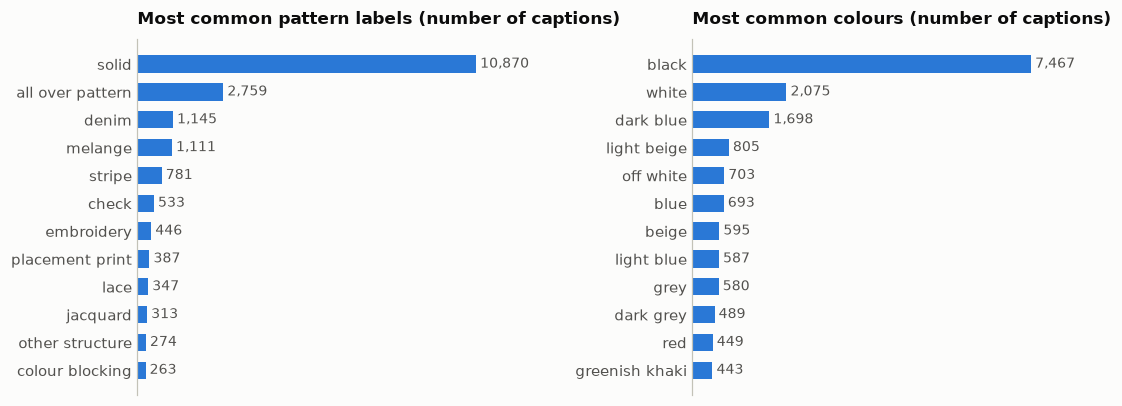

'solid' alone accounts for 53% of captions; black for 36%.


In [4]:
parsed = meta["pattern"].notna()
print(f"Captions that follow the template: {parsed.mean():.1%} ({(~parsed).sum()} do not)")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.45})
patterns = meta["pattern"].value_counts().head(12)
colours = meta["colour"].value_counts().head(12)
ranked_bars(left, patterns.index, patterns.values)
left.set_title("Most common pattern labels (number of captions)")
ranked_bars(right, colours.index, colours.values)
right.set_title("Most common colours (number of captions)")
plt.show()

print(f"'solid' alone accounts for {patterns.get('solid', 0) / len(meta):.0%} of captions; "
      f"black for {colours.get('black', 0) / len(meta):.0%}.")

## Why the raw captions are not alt-text

Alt-text for a product photo should be short, read naturally when spoken, and say only what the
picture shows. The raw captions miss on all three.

### 1. They are too long

A common guideline is to keep alt-text to roughly 125 characters, because a screen reader reads it
in one go and the listener cannot skim.

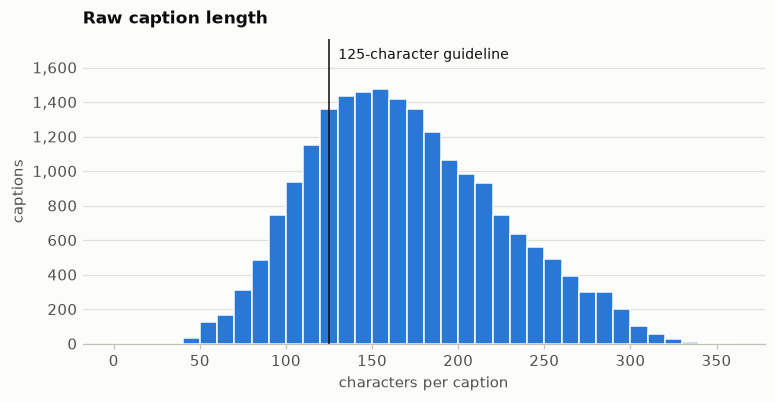

Median length: 163 characters (28 words)
Longer than 125 characters: 76.7%


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
histogram(ax, meta["chars"], bins=range(0, int(meta["chars"].max()) + 10, 10))
reference_line(ax, ALT_TEXT_TARGET_CHARS, f"{ALT_TEXT_TARGET_CHARS}-character guideline")
ax.set_title("Raw caption length")
ax.set_xlabel("characters per caption")
ax.set_ylabel("captions")
plt.show()

over = (meta["chars"] > ALT_TEXT_TARGET_CHARS).mean()
print(f"Median length: {meta['chars'].median():.0f} characters ({meta['words'].median():.0f} words)")
print(f"Longer than {ALT_TEXT_TARGET_CHARS} characters: {over:.1%}")

### 2. They have no punctuation or capital letters

Screen readers pause at commas and full stops. Without them a long caption is read as one
unbroken stream.

In [6]:
has_punctuation = meta["raw_caption"].str.contains(r"[.,;:]")
has_capital = meta["raw_caption"].str.contains(r"[A-Z]")
print(f"Captions containing any of . , ; :   {has_punctuation.mean():.1%}")
print(f"Captions containing a capital letter  {has_capital.mean():.1%}")
print()
print("Longest caption, exactly as it appears in the dataset:")
print(meta.loc[meta["chars"].idxmax(), "raw_caption"])

Captions containing any of . , ; :   0.0%
Captions containing a capital letter  2.3%

Longest caption, exactly as it appears in the dataset:
placement print light beige studio collection overdimensioned t-shirt in soft printed organic cotton jersey with a round rib-trimmed neckline studio collection aw20 is a tribute to the rebellious fearless individual who dares to break the mould - an individual who plays between the extremes and finds their style amongst the androgynous eclectic and creative


### 3. They state things a camera cannot see

The descriptions were written by someone holding the garment and its label: fibre content,
linings, how it feels, what is recycled. A captioning model only gets the photo. If it is trained
to output "organic cotton" it has to guess, and a guess presented as fact is the opposite of an
objective description.

The check below uses a word list (`utils.textnorm.NON_VISIBLE_TERMS`) covering fibre content,
hidden construction, feel, function and fit labels. Fabric types that can be recognised by eye,
such as denim, lace or knit, are deliberately not on it.

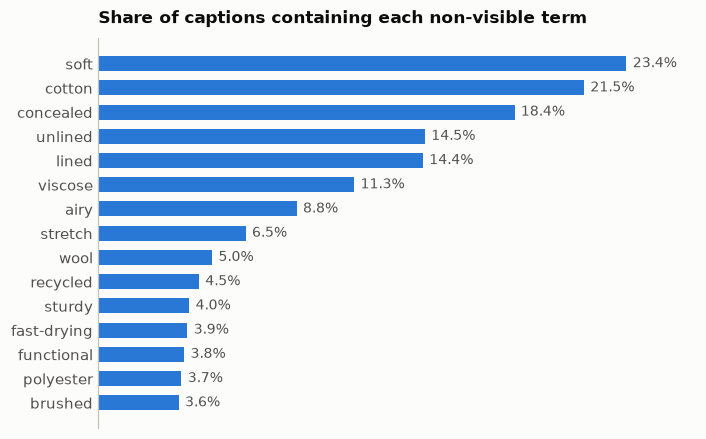

Captions with at least one non-visible term: 87.8%


In [7]:
meta["hidden_terms"] = meta["raw_caption"].map(non_visible_terms)
term_counts = Counter(term for terms in meta["hidden_terms"] for term in terms)
top_terms = pd.Series(dict(term_counts.most_common(15))) / len(meta) * 100

fig, ax = plt.subplots(figsize=(7, 4.6))
ranked_bars(ax, top_terms.index, top_terms.values, value_format="{:.1f}%")
ax.set_title("Share of captions containing each non-visible term")
plt.show()

any_hidden = meta["hidden_terms"].map(bool).mean()
print(f"Captions with at least one non-visible term: {any_hidden:.1%}")

In [8]:
scorecard = pd.DataFrame(
    {
        "what alt-text needs": ["about 125 characters or fewer", "punctuation and sentence case",
                                "only what is visible"],
        "raw captions that meet it": [f"{1 - over:.1%}", f"{(has_punctuation & has_capital).mean():.1%}",
                                      f"{1 - any_hidden:.1%}"],
    },
    index=["length", "readability", "objectivity"],
)
all_three = ((meta["chars"] <= ALT_TEXT_TARGET_CHARS) & has_punctuation & has_capital
             & ~meta["hidden_terms"].map(bool)).mean()
display(scorecard)
print(f"Raw captions that meet all three: {all_three:.1%}")

,what alt-text needs,raw captions that meet it
length,about 125 characters or fewer,23.3%
readability,punctuation and sentence case,0.0%
objectivity,only what is visible,12.2%


Raw captions that meet all three: 0.0%


So the images are usable but the captions are not usable as targets. The next step of the project
(`scripts/02_rewrite_captions.py`) rewrites every caption once with a text-only LLM into a short,
punctuated sentence that keeps the visible facts and drops the rest.

## Colour variants and the grouped split

H&M sells one product in several colours, and every colour shares the same description. If one
colour went into training and another into the test set, the model would be tested on text it had
effectively memorised. The cell below counts how often that happens here: it is rare in this
dataset, but grouping the split by description costs nothing and removes the risk, so all images
that share a description land on the same side.

In [9]:
group_sizes = meta.groupby("body").size()
several = group_sizes[group_sizes > 1]
print(f"Distinct descriptions: {len(group_sizes):,}")
print(f"Descriptions shared by more than one image: {len(several):,} "
      f"(covering {several.sum():,} images, {several.sum() / len(meta):.1%} of the dataset)")

bodies = {name: set(frame["body"]) for name, frame in splits.items()}
overlap = (len(bodies["train"] & bodies["val"]) + len(bodies["train"] & bodies["test"])
           + len(bodies["val"] & bodies["test"]))
print(f"Descriptions appearing in more than one split: {overlap}")
assert overlap == 0

Distinct descriptions: 20,408
Descriptions shared by more than one image: 82 (covering 165 images, 0.8% of the dataset)
Descriptions appearing in more than one split: 0


In [10]:
if len(several):
    biggest = several.sort_values(ascending=False).index[0]
    variants = meta[meta["body"] == biggest].head(4)
    image_grid(variants.to_dict("records"),
               [f"{row.pattern} · {row.colour}" for row in variants.itertuples()],
               caption_lines=2, fontsize=9, title="Several images, one shared description")
    plt.show()
    print("Shared description:", biggest)
else:
    print("No description is shared by more than one image in this dataset.")

Shared description: 5-pocket ankle-length jeans in washed stretch denim with hard-worn details a regular waist zip fly and button and skinny legs


[Output removed from the public repository because it shows H&M product photos. Run this cell to see it.]


## Raw versus rewritten captions

This section fills in once `scripts/02_rewrite_captions.py` has produced `data/alt_text.jsonl`.

Rewritten captions: 20,491; passing every check: 19,363 (94.5%)
Median length: 97 characters; within 125: 89.4%


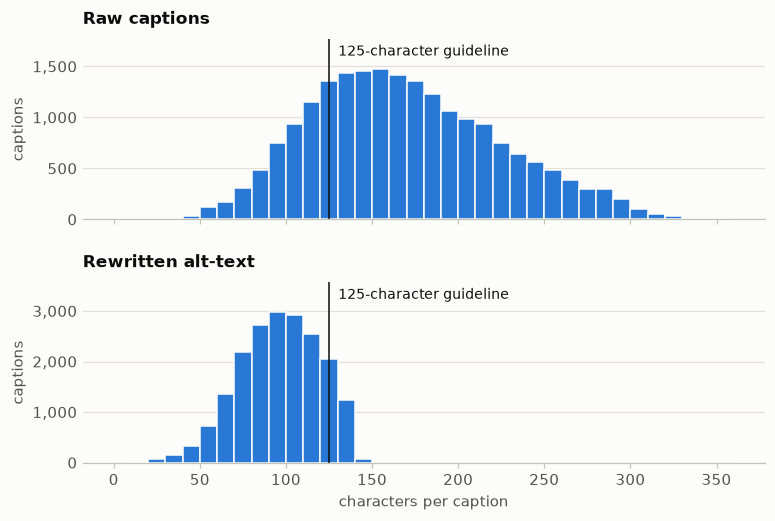

,raw_caption,alt_text
0,denim light blue 5-pocket calf-length skirt in washed denim with worn details and a button fly open at the front,Light blue washed denim 5-pocket calf-length skirt with a button fly.
1,dot white short top in a softly draping patterned viscose weave with a v-neck narrow adjustable shoulder straps buttons down the front and ties at the hem,"White short top with a V-neck, narrow adjustable shoulder straps, buttons down the front and ties at the hem. Dot patterned."
2,solid black blouse in a soft weave with a collar opening at the front with concealed buttons at the top and a pleat at the front to create a gentle drape long sleeves with buttoned cuffs and a rounded hem with slits in the sides,"Black blouse with a collar, front opening, buttons, a pleat, long buttoned sleeves and a rounded hem with side slits."
3,solid dark orange calf-length dress in jersey crepe with a v-neck narrow adjustable shoulder straps and a draped wrapover front with ties at one side,"Dark orange calf-length jersey crepe dress with a V-neck, narrow adjustable shoulder straps and a draped wrapover front."
4,melange grey wide jumper in a soft rib knit with wide ribbing around the neckline dropped shoulders and long slightly wider sleeves slightly longer at the back,"Grey melange wide rib knit jumper with wide ribbing around the neckline, dropped shoulders and long slightly wider sleeves."
5,denim black short 5-pocket skirt in washed denim with worn details a button fly slit at the back and raw-edge hem,"Black washed denim short skirt with 5 pockets, worn details, a button fly and a raw-edge hem."
6,dot black long-sleeved blouse in soft slub cotton jersey with a v-neck decorative gathers at the shoulders and a yoke at the back,"Black long-sleeved blouse with a V-neck, decorative gathers at the shoulders and a dot pattern."
7,solid white wide long-sleeved blouse in a cotton poplin blend with a small collar and opening with a button at the top gathered seam at the top and narrow cuffs with covered buttons and a flared frill longer at the back,"White long-sleeved blouse with a small collar, gathered seam, narrow cuffs with covered buttons and a flared frill."
8,solid dark blue v-neck top in a cotton-blend jersey with short sleeves and sewn-in turn-ups,Dark blue v-neck jersey top with short sleeves and turn-ups.
9,solid pink top in soft sweatshirt fabric made from a cotton blend long raglan sleeves and ribbing around the neckline cuffs and hem,"Pink sweatshirt top with long raglan sleeves and ribbing around the neckline, cuffs and hem."


In [11]:
alt_path = DATA_DIR / "alt_text.jsonl"
if alt_path.exists():
    alt = pd.DataFrame(read_jsonl(alt_path))
    kept = alt[alt["ok"]]
    print(f"Rewritten captions: {len(alt):,}; passing every check: {len(kept):,} ({len(kept) / len(alt):.1%})")
    print(f"Median length: {kept['alt_text'].str.len().median():.0f} characters; "
          f"within {ALT_TEXT_TARGET_CHARS}: {(kept['alt_text'].str.len() <= ALT_TEXT_TARGET_CHARS).mean():.1%}")

    fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"hspace": 0.35})
    bins = range(0, int(meta["chars"].max()) + 10, 10)
    histogram(axes[0], meta["chars"], bins=bins)
    axes[0].set_title("Raw captions")
    histogram(axes[1], kept["alt_text"].str.len(), bins=bins)
    axes[1].set_title("Rewritten alt-text")
    axes[1].set_xlabel("characters per caption")
    for ax in axes:
        reference_line(ax, ALT_TEXT_TARGET_CHARS, f"{ALT_TEXT_TARGET_CHARS}-character guideline")
        ax.set_ylabel("captions")
    plt.show()

    display(kept.sample(10, random_state=3)[["raw_caption", "alt_text"]].reset_index(drop=True))
else:
    print("data/alt_text.jsonl does not exist yet; run step 2 (the caption rewrite) to fill this in.")